---
title: "Data summary of my five flux towers"
author: "Kornelius Müller"
date: 17.11.26
format:
  html:
    toc: true
    embed-resources: true
execute:
  warning: false
---


In [52]:
import pandas as pd
from pathlib import Path
import zipfile
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from matplotlib.ticker import PercentFormatter
import numpy as np



In [ ]:
path = "/home/pat/Schreibtisch/Dokumente/Uni Freiburg/WS 26 27/GitRep/datascience_env_monit/scripts/data/raw"

keep = ["TIMESTAMP_START", "TIMESTAMP_END", "TA_F", "SW_IN_F", "VPD_F", "P_F",
        "NETRAD", "G_F_MDS", "H_F_MDS", "H_F_MDS_QC", "LE_F_MDS", "LE_F_MDS_QC",
        "NEE_VUT_REF", "NEE_VUT_REF_QC", "GPP_NT_VUT_REF", "RECO_NT_VUT_REF", "NEE_CUT_REF" ]

zip_file = sorted(Path("/home/pat/Schreibtisch/Dokumente/Uni Freiburg/WS 26 27/GitRep/datascience_env_monit/scripts/data/raw").glob("*.zip"))[1]
with zipfile.ZipFile(zip_file) as z:
    hh_name = [n for n in z.namelist() if "FLUXMET_HH" in n][0]
    with z.open(hh_name) as f:
        hh = pd.read_csv(f, na_values=[-9999],
                         usecols=lambda c: c in keep,
                         dtype={"TIMESTAMP_START": str, "TIMESTAMP_END": str})

hh["time"] = pd.to_datetime(hh["TIMESTAMP_START"], format="%Y%m%d%H%M")
print(len(hh), hh["time"].min(), hh["time"].max())
print((hh["NEE_VUT_REF_QC"] == 0).mean())    # share of measured NEE

210384 2013-01-01 00:00:00 2024-12-31 23:30:00
0.28946117575481023


In [ ]:
def readzip(folder, keep):
    hh = pd.DataFrame()
    zip_files = sorted(Path(folder).glob("*.zip"))

    for zip_file in zip_files:
        with zipfile.ZipFile(zip_file) as z:
            hh_names = [
                name for name in z.namelist()
                if "FLUXMET_HH" in name
            ]

            for hh_name in hh_names:
                with z.open(hh_name) as f:
                    current = pd.read_csv(
                        f,
                        na_values=[-9999],
                        usecols=lambda c: c in keep,
                        dtype={
                            "TIMESTAMP_START": str,
                            "TIMESTAMP_END": str,
                        },
                    )

                current["time"] = pd.to_datetime(
                    current["TIMESTAMP_START"],
                    format="%Y%m%d%H%M",
                )
                current["site"] = hh_name.split("_FLUXNET_FLUXMET_HH")[0]
                current['I']

                hh = pd.concat([hh, current], ignore_index=True)

    return hh

hh_df = readzip(path,keep)

In [23]:
print(hh_df.head())

  TIMESTAMP_START TIMESTAMP_END   TA_F  SW_IN_F  VPD_F    P_F  NETRAD  \
0    200801010000  200801010030 -5.472      0.0  0.477  0.034     NaN   
1    200801010030  200801010100 -5.525      0.0  0.500  0.034     NaN   
2    200801010100  200801010130 -5.578      0.0  0.524  0.015     NaN   
3    200801010130  200801010200 -5.608      0.0  0.524  0.015     NaN   
4    200801010200  200801010230 -5.638      0.0  0.523  0.013     NaN   

   G_F_MDS  LE_F_MDS  LE_F_MDS_QC  H_F_MDS  H_F_MDS_QC  RECO_NT_VUT_REF  \
0      NaN       NaN          NaN      NaN         NaN              NaN   
1      NaN       NaN          NaN      NaN         NaN              NaN   
2      NaN       NaN          NaN      NaN         NaN              NaN   
3      NaN       NaN          NaN      NaN         NaN              NaN   
4      NaN       NaN          NaN      NaN         NaN              NaN   

   GPP_NT_VUT_REF                time        site  NEE_VUT_REF  NEE_VUT_REF_QC  
0             NaN 2008-01-01 

In [36]:
def unpack_data(path, keep):
    container_list = sorted(Path(path).glob("*.zip"))
    dflist = []

    for container in container_list:
        with zipfile.ZipFile(container) as archive:
            names = archive.namelist()
            ds_name = next(name for name in names if "FLUXMET_HH" in name)
            bif_name = next(name for name in names if "_BIF_" in name)
            bif = pd.read_csv(archive.open(bif_name))
            igbp_code = bif.loc[bif["VARIABLE"].eq("IGBP"), "DATAVALUE"].iloc[0]

            dataset = pd.read_csv(
                archive.open(ds_name),
                na_values=[-9999],
                usecols=lambda s: s in keep,
                dtype={"TIMESTAMP_START": str, "TIMESTAMP_END": str},
            )

        dataset["time"] = pd.to_datetime(dataset["TIMESTAMP_START"], format="%Y%m%d%H%M")
        dataset["site"] = ds_name.split("_FLUXNET_FLUXMET_HH")[0]
        dataset["dsname"] = ds_name
        dataset["IGBP"] = igbp_code
        dflist.append(dataset)

    return pd.concat(dflist)
hh_df = unpack_data(path, keep)

## Part C

### C1


In [37]:
snap = pd.read_csv('/home/pat/Schreibtisch/Dokumente/Uni Freiburg/WS 26 27/GitRep/datascience_env_monit/scripts/data/snapshots/fluxnet_shuttle_snapshot_20261113T111612.csv')
# print(snap.head())

In [38]:
IGBP_CLASSES = {
    "ENF": "Evergreen Needleleaf Forests",
    "EBF": "Evergreen Broadleaf Forests",
    "DNF": "Deciduous Needleleaf Forests",
    "DBF": "Deciduous Broadleaf Forests",
    "MF":  "Mixed Forests",
    "CSH": "Closed Shrublands",
    "OSH": "Open Shrublands",
    "WSA": "Woody Savannas",
    "SAV": "Savannas",
    "GRA": "Grasslands",
    "WET": "Permanent Wetlands",
    "CRO": "Croplands",
    "URB": "Urban and Built-Up Lands",
    "CVM": "Cropland/Natural Vegetation Mosaics",
    "SNO": "Snow and Ice",
    "BSV": "Barren Sparse Vegetation",
    "WAT": "Water Bodies",
                }

countries_dict = {  
                    "CA" : "Canada",
                    "US" : "USA",
                    "FR" : "France",
                    "CN" : "China",
                    "AU" : "Australia"
                }

countries_acronym = hh_df["site"].str.split("_").str[-1].str.split("-").str[0]
hh_df["country"] = countries_acronym.map(countries_dict)
hh_df["IGBP_Class"] = hh_df["IGBP"].map(IGBP_CLASSES)

In [45]:
print(hh_df['country'])


0            USA
1            USA
2            USA
3            USA
4            USA
           ...  
403243    France
403244    France
403245    France
403246    France
403247    France
Name: country, Length: 1858464, dtype: str


In [50]:
snapshot = pd.read_csv(Path("/home/pat/Schreibtisch/Dokumente/Uni Freiburg/WS 26 27/GitRep/datascience_env_monit/scripts/data/snapshots/fluxnet_shuttle_snapshot_20261113T111612.csv"))

columns = [
    "site_id",
    "site_name",
    "igbp",
    "first_year",
    "last_year",
    "data_hub",
    "location_lat",
    "location_long",
    "product_citation",
    ]

site_ids = hh_df["site"].str.split("_").str[-1].unique()

tower_table = (
    snapshot.loc[snapshot["site_id"].isin(site_ids), columns]
    .drop_duplicates(subset="site_id")
    .assign(country=lambda df: df["site_id"].str.extract(r"^([A-Z]{2})-")[0])
    .rename(columns={
        "site_id": "Site ID",
        "site_name": "Name",
        "igbp": "IGBP class",
        "first_year": "First year",
        "last_year": "Last year",
        "data_hub": "Hub",
        "location_lat": "Latitude",
        "location_long": "Longitude",
        "product_citation": "Data citation",
        "country": "Country code"
    })
    .reset_index(drop=True)
)

display(tower_table)

,Site ID,Name,IGBP class,First year,Last year,Hub,Latitude,Longitude,Data citation,Country code
0,US-UiD,University of Illinois Restored Native Prairie,GRA,2008,2024,AmeriFlux,40.064600,-88.198500,"Carl Bernacchi, Bethany Blakely, Caitlin Moore...",US
1,FR-Gri,Grignon,CRO,2004,2026,ICOS,48.844220,1.951910,"Buysse, P., Loubet, B., Depuydt, J., Durand, B...",FR
2,DE-Hai,Hainich,DBF,2000,2025,ICOS,51.079212,10.452168,"Knohl, A., Tiedemann, F., Klosterhalfen, A., M...",DE
3,RU-Fyo,Fyodorovskoye,ENF,1998,2025,ICOS,56.461530,32.922085,"Varlagin, A. (2026). Fluxnet Archive Product f...",RU
4,CN-Sdq,Sidaoqiao,OSH,2013,2024,ICOS,42.001190,101.137410,"Liu, S., Che, T., Xu, Z. (2026). Fluxnet Archi...",CN


In [49]:
# simple plot

fig = px.scatter_geo(
    tower_table,
    lat="Latitude",
    lon="Longitude",
    hover_name="Site ID",
    hover_data=["Name", "IGBP class"],
    projection="natural earth",
    title="Locations of my flux towers"
)

fig.show()

### C2

For each site and year, the share of half hours in which NEE was measured (NEE_VUT_REF_QC == 0). Show it as a heat map: sites on the y-axis, years on the x-axis, colour = share measured. Add one sentence: which site and years have the best data?

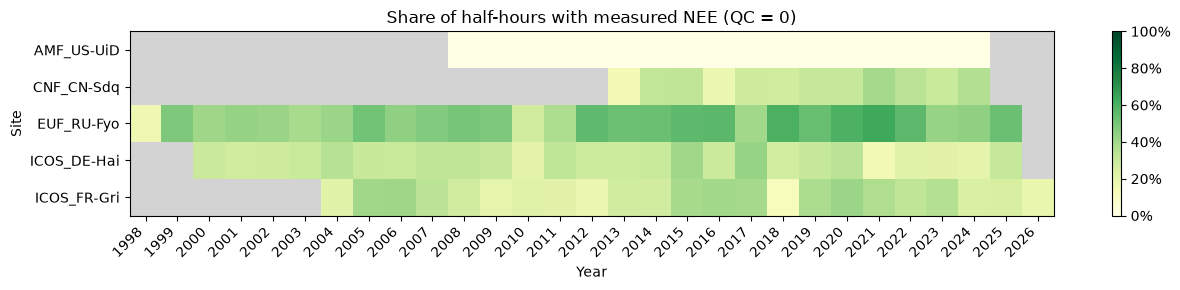

The highest measured-NEE share was 63.3% at EUF_RU-Fyo in 2021.


In [54]:
# True where NEE was measured (QC == 0); NaN QC values count as not measured.
data = hh_df.assign(
    year=hh_df["time"].dt.year,
    measured=hh_df["NEE_VUT_REF_QC"].eq(0),
)

nee_share = (
    data.groupby(["site", "year"])["measured"]
    .mean()
    .unstack("year")
    .sort_index()
)

# Heat map
values = nee_share.to_numpy(dtype=float)
cmap = plt.cm.YlGn.copy()
cmap.set_bad("lightgray")

fig, ax = plt.subplots(
    figsize=(max(10, len(nee_share.columns) * 0.45),
             max(3, len(nee_share.index) * 0.6))
)
image = ax.imshow(
    np.ma.masked_invalid(values),
    aspect="auto",
    cmap=cmap,
    vmin=0,
    vmax=1,
)

ax.set_xticks(np.arange(len(nee_share.columns)))
ax.set_xticklabels(nee_share.columns, rotation=45, ha="right")
ax.set_yticks(np.arange(len(nee_share.index)))
ax.set_yticklabels(nee_share.index)
ax.set_xlabel("Year")
ax.set_ylabel("Site")
ax.set_title("Share of half-hours with measured NEE (QC = 0)")

colorbar = fig.colorbar(image, ax=ax)
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(1))

plt.tight_layout()
plt.show()

# Print the site-year cell(s) with the highest measured share
shares = nee_share.stack()
best_share = shares.max()
best_cells = shares[np.isclose(shares, best_share)]

best_labels = ", ".join(
    f"{site} in {year}" for site, year in best_cells.index
)
print(
    f"The highest measured-NEE share was {best_share:.1%} at {best_labels}."
)

### C3


A table per site with mean, minimum, maximum and % missing for TA_F, SW_IN_F, VPD_F, P_F, NEE_VUT_REF, GPP_NT_VUT_REF, RECO_NT_VUT_REF, H_F_MDS and LE_F_MDS. Give the units in the column headers. For precipitation, give the mean annual sum instead of the mean.

In [55]:
# Variable names and units for half-hourly values
units = {
    "TA_F": "°C",
    "SW_IN_F": "W m⁻²",
    "VPD_F": "hPa",
    "P_F": "mm per half-hour",
    "NEE_VUT_REF": "µmol CO₂ m⁻² s⁻¹",
    "GPP_NT_VUT_REF": "µmol CO₂ m⁻² s⁻¹",
    "RECO_NT_VUT_REF": "µmol CO₂ m⁻² s⁻¹",
    "H_F_MDS": "W m⁻²",
    "LE_F_MDS": "W m⁻²",
}

df = hh_df.copy()
df["time"] = pd.to_datetime(df["time"])
df["year"] = df["time"].dt.year

# Average annual precipitation total per site.
# Each year's sum uses available (non-missing) half-hourly P_F values.
annual_precip = (
    df.groupby(["site", "year"])["P_F"]
      .sum(min_count=1)
      .groupby("site")
      .mean()
)

summary = pd.DataFrame(index=sorted(df["site"].dropna().unique()))

for variable, unit in units.items():
    values = df.groupby("site")[variable]

    if variable == "P_F":
        summary[f"{variable} mean annual sum (mm/year)"] = annual_precip
    else:
        summary[f"{variable} mean ({unit})"] = values.mean()

    summary[f"{variable} minimum ({unit})"] = values.min()
    summary[f"{variable} maximum ({unit})"] = values.max()
    summary[f"{variable} missing (%)"] = values.apply(
        lambda series: series.isna().mean() * 100
    )

summary = summary.rename_axis("Site").reset_index()
display(summary)

,Site,TA_F mean (°C),TA_F minimum (°C),TA_F maximum (°C),TA_F missing (%),SW_IN_F mean (W m⁻²),SW_IN_F minimum (W m⁻²),SW_IN_F maximum (W m⁻²),SW_IN_F missing (%),VPD_F mean (hPa),...,RECO_NT_VUT_REF maximum (µmol CO₂ m⁻² s⁻¹),RECO_NT_VUT_REF missing (%),H_F_MDS mean (W m⁻²),H_F_MDS minimum (W m⁻²),H_F_MDS maximum (W m⁻²),H_F_MDS missing (%),LE_F_MDS mean (W m⁻²),LE_F_MDS minimum (W m⁻²),LE_F_MDS maximum (W m⁻²),LE_F_MDS missing (%)
0,AMF_US-UiD,11.320184,-27.598,37.495,0.000000,171.475435,0.0,1125.000,0.000000,4.652460,...,NaN,100.000000,15.787366,-151.913,375.004,50.643451,58.650034,-169.9480,672.382,50.643451
1,CNF_CN-Sdq,11.038898,-26.103,40.777,0.000000,205.166193,0.0,1065.670,0.000000,14.027581,...,7.32795,4.666705,41.628358,-159.856,540.387,3.992699,41.695219,-140.0690,834.278,4.657198
2,EUF_RU-Fyo,5.584958,-34.977,36.707,0.000000,109.186482,0.0,991.353,0.000000,2.813242,...,22.41000,1.962738,22.398541,-206.735,606.987,1.310257,28.182100,-93.5036,595.334,1.310257
3,ICOS_DE-Hai,8.763756,-18.580,35.365,0.000000,123.858522,0.0,1090.430,0.000000,3.703410,...,10.67380,1.380260,16.914753,-286.984,733.646,1.000097,27.770618,-220.3800,735.220,1.749017
4,ICOS_FR-Gri,11.773241,-12.740,40.040,1.559338,139.891462,0.0,1105.370,1.559338,4.217582,...,19.95150,9.628318,11.630866,-297.197,962.932,5.062393,33.940705,-247.6450,771.899,5.062641


### C4


Aggregate the half-hourly data to daily values yourself and plot daily NEE, GPP and RECO over the whole record, one panel per site.

Unit conversion: 1 µmol CO₂ m⁻² s⁻¹ = 1.0378 g C m⁻² d⁻¹ (× 86 400 s × 12.011 g mol⁻¹ × 10⁻⁶). So a daily mean in µmol m⁻² s⁻¹ × 1.0378 gives g C m⁻² d⁻¹.

Check your aggregation once against the daily FLUXMET_DD file for one site

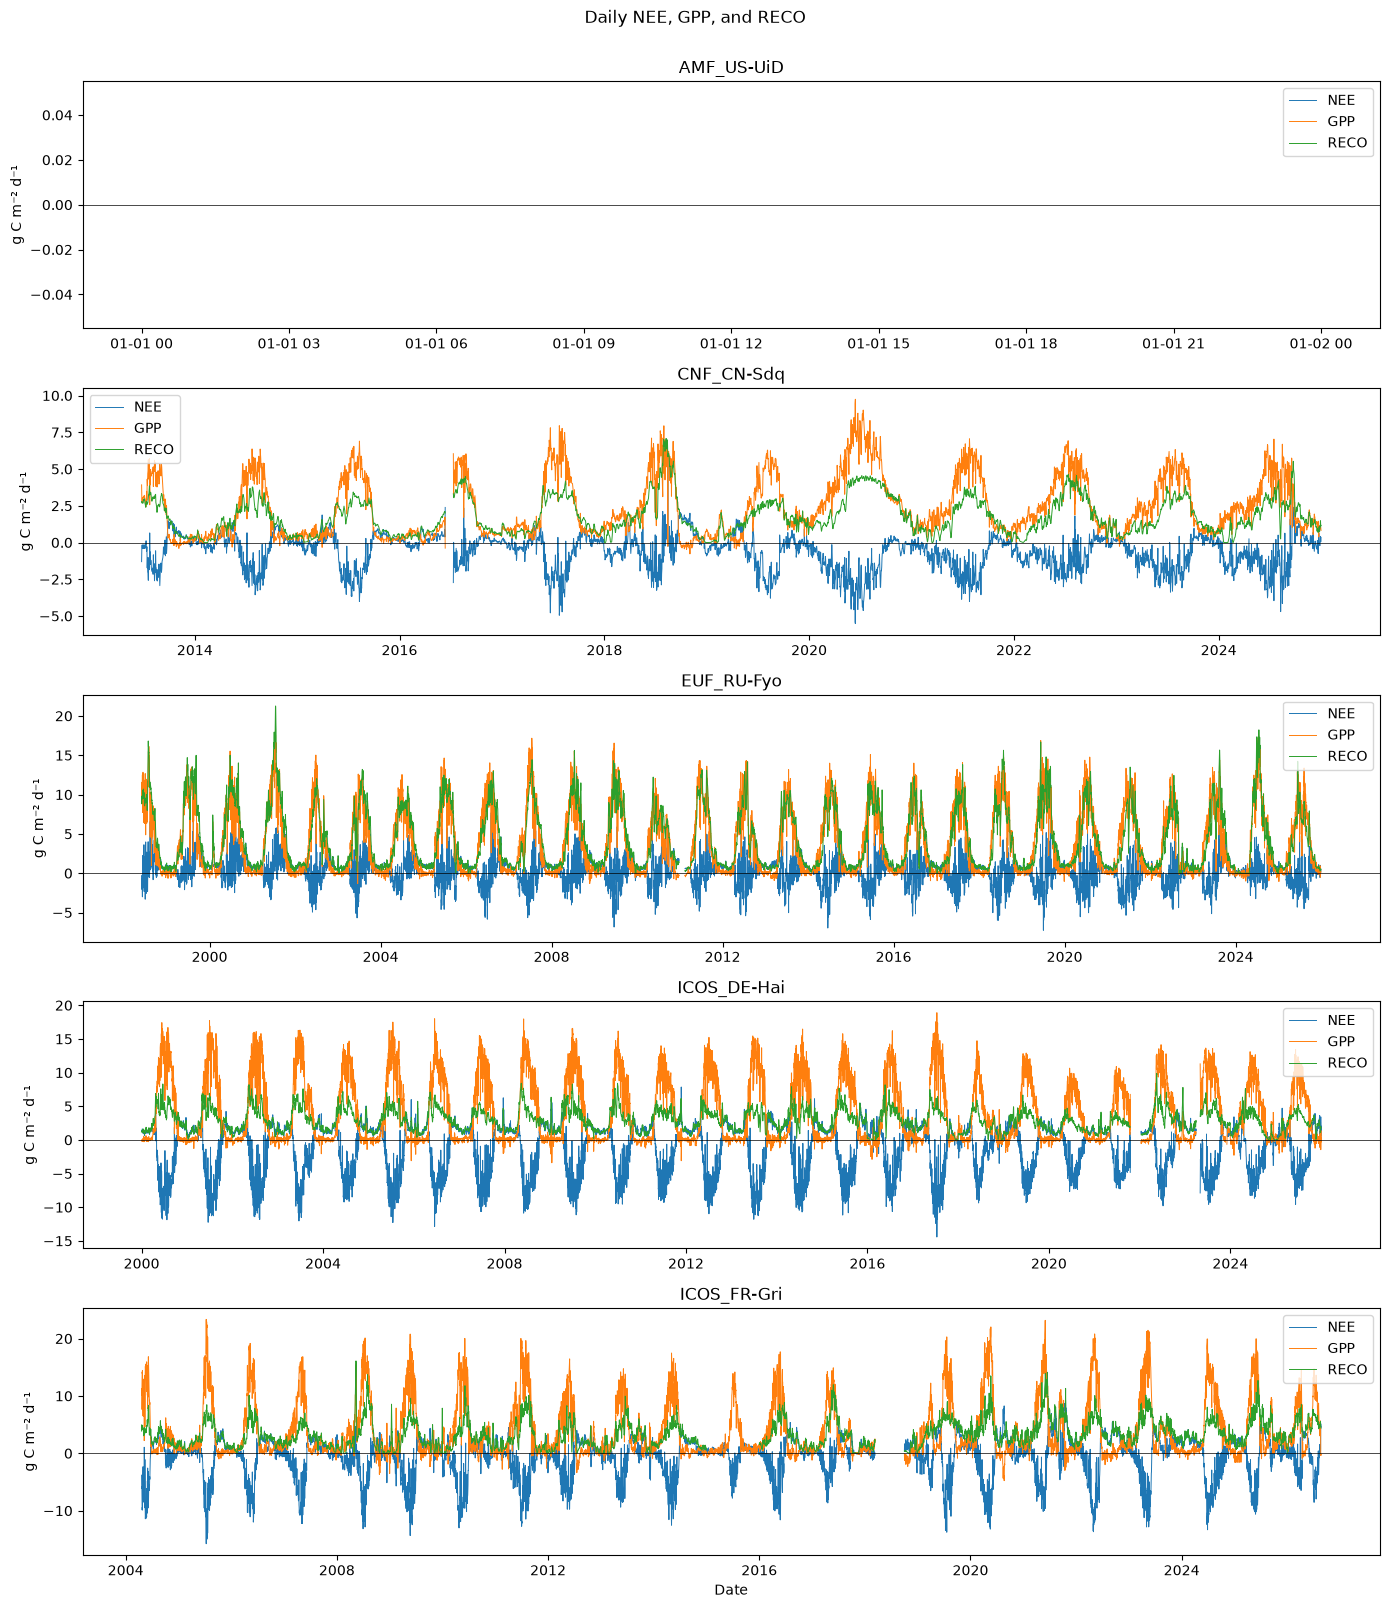

In [58]:
flux_columns = {
    "NEE_VUT_REF": "NEE",
    "GPP_NT_VUT_REF": "GPP",
    "RECO_NT_VUT_REF": "RECO",
}

# Ensure these variables are included in `keep` before rebuilding master_df:
# "NEE_CUT_REF", "GPP_NT_VUT_REF", "RECO_NT_VUT_REF"

data = hh_df.copy()
data["time"] = pd.to_datetime(data["time"])

# Daily mean of the half-hourly fluxes, converted to g C m⁻² d⁻¹.
daily = (
    data.groupby(["site", pd.Grouper(key="time", freq="D")])[list(flux_columns)]
        .mean()
        .mul(1.0378)
        .reset_index()
)

sites = sorted(daily["site"].unique())
fig, axes = plt.subplots(
    len(sites), 1,
    figsize=(14, 3.2 * len(sites)),
    sharex=False,
    squeeze=False,
)

for ax, site in zip(axes[:, 0], sites):
    site_data = daily[daily["site"] == site]

    for column, label in flux_columns.items():
        ax.plot(site_data["time"], site_data[column], label=label, linewidth=0.7)

    ax.set_title(site)
    ax.set_ylabel("g C m⁻² d⁻¹")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.legend()

axes[-1, 0].set_xlabel("Date")
fig.suptitle("Daily NEE, GPP, and RECO", y=1.002)
fig.tight_layout()
plt.show()

In [62]:
print(hh_df.columns.tolist())

['TIMESTAMP_START', 'TIMESTAMP_END', 'TA_F', 'SW_IN_F', 'VPD_F', 'P_F', 'NETRAD', 'G_F_MDS', 'LE_F_MDS', 'LE_F_MDS_QC', 'H_F_MDS', 'H_F_MDS_QC', 'RECO_NT_VUT_REF', 'GPP_NT_VUT_REF', 'time', 'site', 'dsname', 'IGBP', 'NEE_VUT_REF', 'NEE_VUT_REF_QC', 'country', 'IGBP_Class']


For the first Tower, there is no NEE_VUT_REF column.

### C5


The mean daily course (hour of day on the x-axis) of NEE and LE for each season, all five sites in one figure. Careful: seasons are reversed in the southern hemisphere. Use latitude to define the seasons correctly and say how you did it.

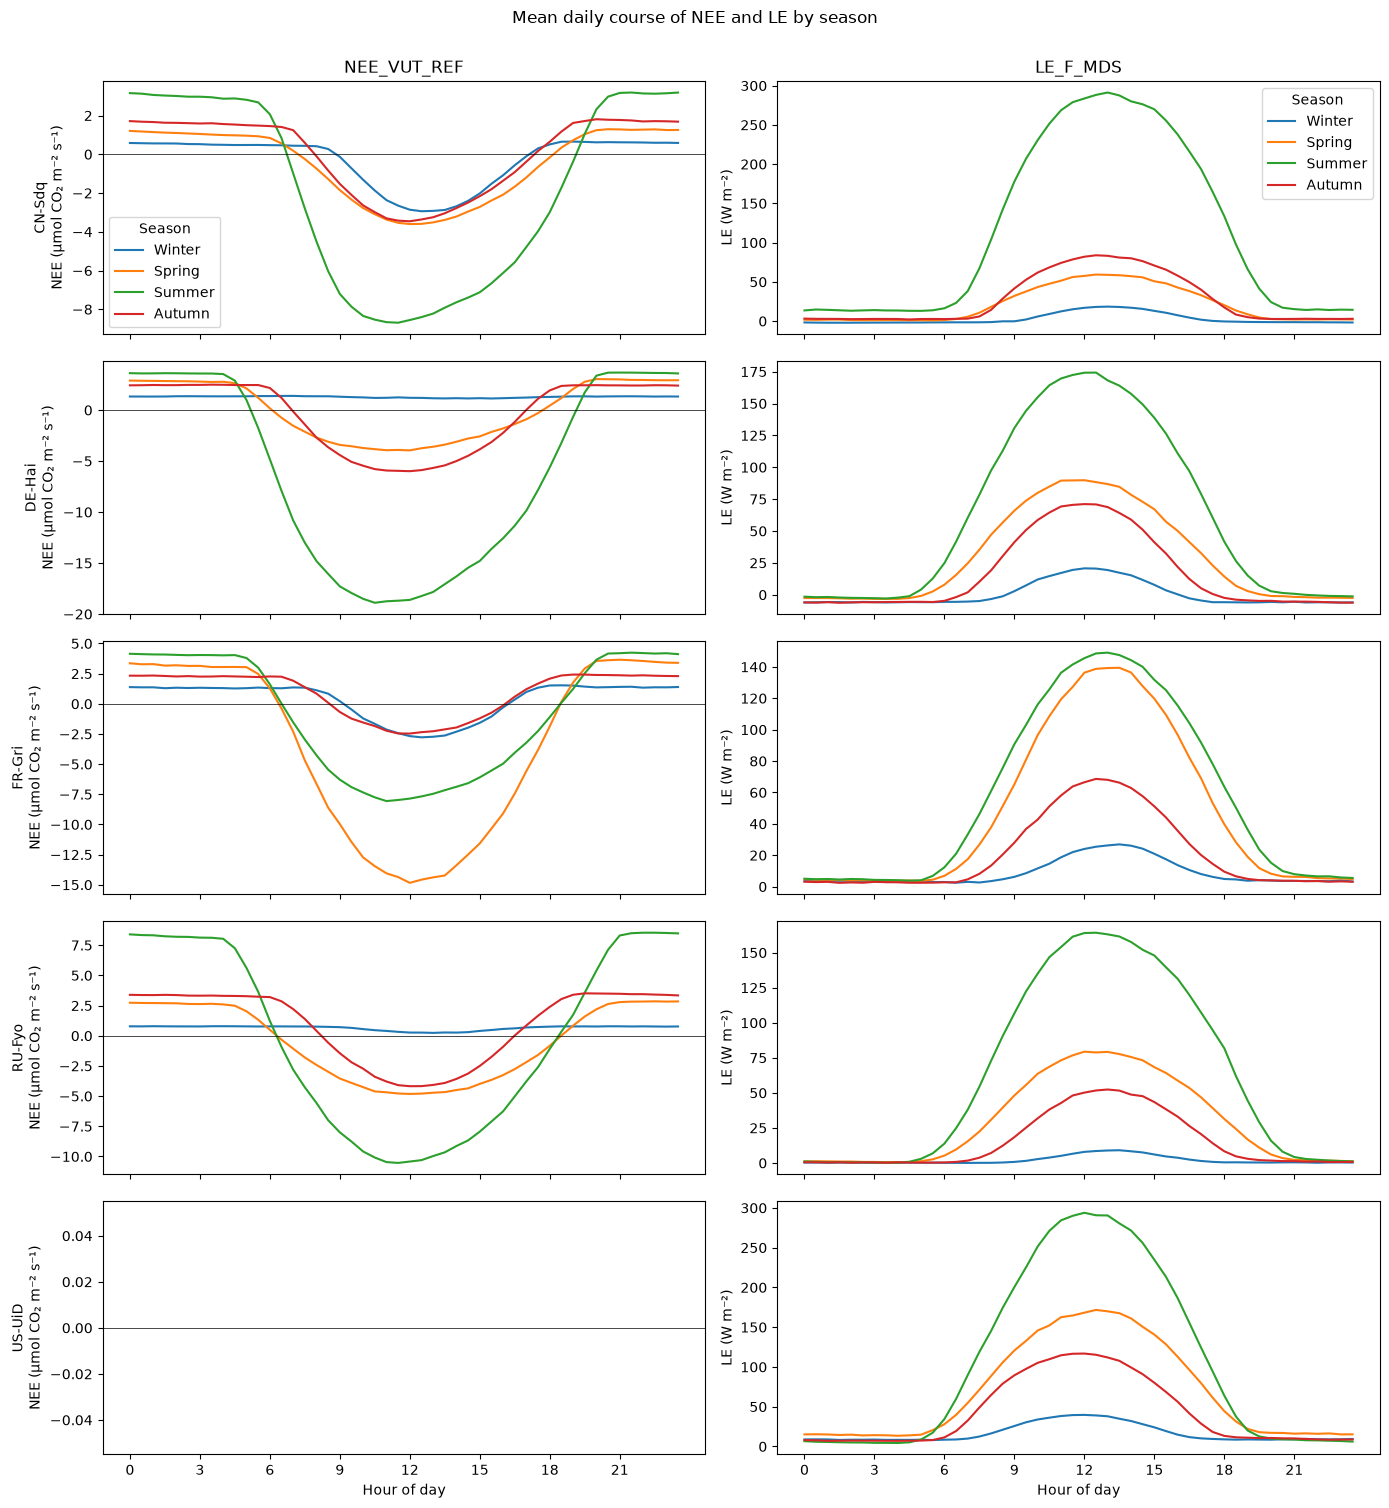

In [61]:

# Map each site in hh_df to its latitude in tower_table.
data["site_id"] = data["site"].str.rsplit("_", n=1).str[-1]

site_latitudes = tower_table.set_index("Site ID")["Latitude"]
data["latitude"] = data["site_id"].map(site_latitudes)

if data["latitude"].isna().any():
    missing_sites = data.loc[data["latitude"].isna(), "site_id"].unique()
    raise ValueError(f"Could not find latitude for these sites: {missing_sites}")

data["time"] = pd.to_datetime(data["time"])
data["month"] = data["time"].dt.month

# Use decimal hours so half-hourly observations appear at 0.0, 0.5, 1.0, etc.
data["hour"] = data["time"].dt.hour + data["time"].dt.minute / 60

north_seasons = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}
south_seasons = {
    12: "Summer", 1: "Summer", 2: "Summer",
    3: "Autumn", 4: "Autumn", 5: "Autumn",
    6: "Winter", 7: "Winter", 8: "Winter",
    9: "Spring", 10: "Spring", 11: "Spring",
}

data["season"] = data["month"].map(north_seasons)
southern_hemisphere = data["latitude"] < 0
data.loc[southern_hemisphere, "season"] = (
    data.loc[southern_hemisphere, "month"].map(south_seasons)
)

# Average each variable by site, season, and half-hour of day.
nee_column = "NEE_VUT_REF"
le_column = "LE_F_MDS"
season_order = ["Winter", "Spring", "Summer", "Autumn"]

diurnal = (
    data.groupby(["site_id", "season", "hour"])[[nee_column, le_column]]
        .mean()
        .reset_index()
)

sites = sorted(diurnal["site_id"].unique())
fig, axes = plt.subplots(
    nrows=len(sites),
    ncols=2,
    figsize=(14, 3 * len(sites)),
    sharex=True,
    squeeze=False,
)

for row, site in enumerate(sites):
    site_data = diurnal[diurnal["site_id"] == site]

    for season in season_order:
        season_data = site_data[site_data["season"] == season].sort_values("hour")
        if season_data.empty:
            continue

        axes[row, 0].plot(
            season_data["hour"], season_data[nee_column], label=season
        )
        axes[row, 1].plot(
            season_data["hour"], season_data[le_column], label=season
        )

    axes[row, 0].set_ylabel(f"{site}\nNEE (µmol CO₂ m⁻² s⁻¹)")
    axes[row, 1].set_ylabel("LE (W m⁻²)")
    axes[row, 0].axhline(0, color="black", linewidth=0.5)

    if row == 0:
        axes[row, 0].set_title("NEE_VUT_REF")
        axes[row, 1].set_title("LE_F_MDS")
        axes[row, 0].legend(title="Season")
        axes[row, 1].legend(title="Season")

axes[-1, 0].set_xlabel("Hour of day")
axes[-1, 1].set_xlabel("Hour of day")
axes[-1, 0].set_xticks(range(0, 24, 3))
axes[-1, 1].set_xticks(range(0, 24, 3))

fig.suptitle("Mean daily course of NEE and LE by season", y=1.002)
fig.tight_layout()
plt.show()

### C6



    Energy balance for one tower: scatter of H_F_MDS + LE_F_MDS against NETRAD − G_F_MDS, using only half hours where H and LE were measured (_QC == 0). Add the 1:1 line and the slope of a linear fit. Some towers have no NETRAD or G; pick one that has them.
    5–8 sentences comparing your towers: which takes up the most carbon per year, which has the largest seasonal cycle, which surprised you, and how much of the data is gap-filled.


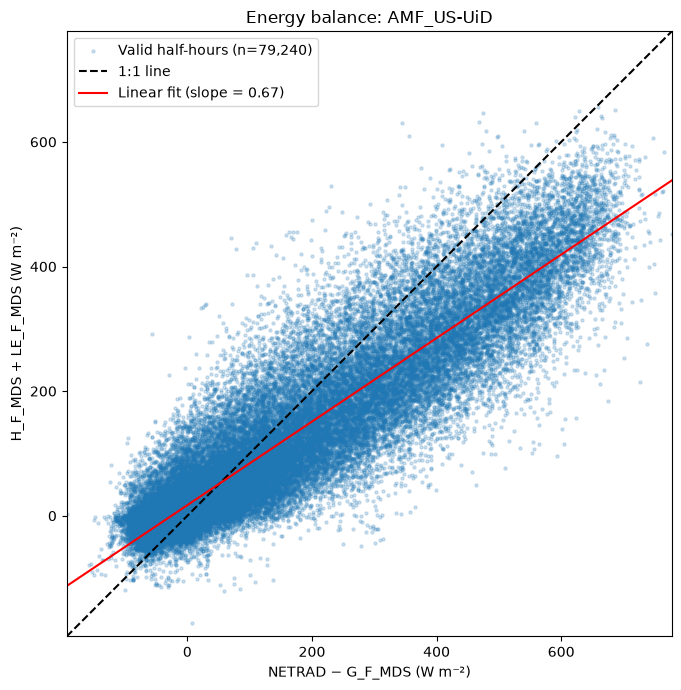

AMF_US-UiD: 79,240 valid half-hours; fitted slope = 0.670


In [ ]:
site = "AMF_US-UiD"

site_data = hh_df.loc[hh_df["site"] == site].copy()

# Keep half-hours where both turbulent fluxes passed QC
# and all energy-balance values are present.
valid = (
    site_data["H_F_MDS_QC"].eq(0)
    & site_data["LE_F_MDS_QC"].eq(0)
    & site_data[["NETRAD", "G_F_MDS", "H_F_MDS", "LE_F_MDS"]]
        .notna()
        .all(axis=1)
)

x = (site_data.loc[valid, "NETRAD"] - site_data.loc[valid, "G_F_MDS"])
y = (site_data.loc[valid, "H_F_MDS"] + site_data.loc[valid, "LE_F_MDS"])

# Linear fit: y = slope*x + intercept
slope, intercept = np.polyfit(x, y, 1)

# Shared axis limits so the 1:1 line is meaningful.
limits = [
    min(x.min(), y.min()),
    max(x.max(), y.max()),
]
line_x = np.linspace(*limits, 200)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(x, y, s=5, alpha=0.2, label=f"Valid half-hours (n={len(x):,})")
ax.plot(limits, limits, "k--", label="1:1 line")
ax.plot(
    line_x,
    slope * line_x + intercept,
    color="red",
    label=f"Linear fit (slope = {slope:.2f})",
)

ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("NETRAD − G_F_MDS (W m⁻²)")
ax.set_ylabel("H_F_MDS + LE_F_MDS (W m⁻²)")
ax.set_title(f"Energy balance: {site}")
ax.legend()
plt.tight_layout()
plt.show()

print(f"{site}: {len(x):,} valid half-hours; fitted slope = {slope:.3f}")

#### 6.2


Using NEE_CUT_REF consistently and averaging site-years with at least 90% non-missing half-hours, ICOS_DE-Hai had the strongest mean annual carbon uptake at −507.5 g C m⁻² yr⁻¹; negative NEE indicates uptake. AMF_US-UiD averaged −345.5, ICOS_FR-Gri −297.8, and CNF_CN-Sdq −249.0 g C m⁻² yr⁻¹, while EUF_RU-Fyo averaged +74.3 g C m⁻² yr⁻¹, indicating a net carbon source. ICOS_DE-Hai also had the largest seasonal cycle, with a 7.72 g C m⁻² d⁻¹ range between its seasonal mean NEE values. One result that surprised me was that EUF_RU-Fyo was the only site with positive mean annual NEE, while the other four showed net uptake. The share of non-missing NEE observations classified as gap-filled was 47.9% at AMF_US-UiD, 52.4% at EUF_RU-Fyo, 70.0% at ICOS_FR-Gri, 70.3% at CNF_CN-Sdq, and 71.1% at ICOS_DE-Hai. These annual totals include both measured and gap-filled NEE values; the gap-filled percentages count records with QC greater than zero among records with a QC value.

### Citations

The following FLUXNET data products were used:

US-UiD — University of Illinois Restored Native Prairie: Carl Bernacchi, Bethany Blakely, Caitlin Moore, Taylor Pederson (2026), AmeriFlux FLUXNET-1F US-UiD University of Illinois Restored Native Prairie, Ver. v1.3_r1 (2008–2024), AmeriFlux AMP (Dataset). https://doi.org/10.17190/AMF/3027339
CN-Sdq — Sidaoqiao: Liu, S., Che, T., Xu, Z. (2026). Fluxnet Archive Product from Sidaoqiao, 2013–2024, FLUXNET. https://hdl.handle.net/11676/3lCvpR-G0sl29NE-OD2rgvf7
RU-Fyo — Fyodorovskoye: Varlagin, A. (2026). Fluxnet Archive Product from Fyodorovskoye, 1998–2025, FLUXNET. https://hdl.handle.net/11676/WDPOlLyjxJ7H43yO9QgAoOfj
DE-Hai — Hainich: Knohl, A., Tiedemann, F., Klosterhalfen, A., Markwitz, C., Fellert, D., Herbst, M., Kolle, O., Kreilein, H., Kutsch, W., Kutsch, W., Rebmann, C., Siebicke, L. (2026). Fluxnet Archive Product from Hainich, 2000–2025, FLUXNET. https://hdl.handle.net/11676/VsQ1NTQTcEO5zRyfZjrBtkQa
FR-Gri — Grignon: Buysse, P., Loubet, B., Depuydt, J., Durand, B., Gueudet, J.-C., Kalalian, C. (2026). Fluxnet Archive Product from Grignon, 2004-01-01–2026-09-06, FLUXNET. https://hdl.handle.net/11676/XSI0ETkKyVVydpJuL7ro3_rQ
The FLUXNET data processing pipeline is described in Pastorello, G., Trotta, C., Canfora, E. et al. (2020). “The FLUXNET2015 dataset and the ONEFlux processing pipeline for eddy covariance data.” Scientific Data, 7, 225. https://doi.org/10.1038/s41597-020-0534-3


Acknowledgement: FLUXNET data products were produced and harmonized by eddy covariance regional networks and data processing centers, including AmeriFlux, ChinaFlux, European Fluxes Database, ICOS, JapanFlux, KoFlux, OzFlux, SAEON, and TERN. These products also include a modified version of ERA5 hourly data provided by the Copernicus Climate Change Service.

